### Prueba - Modelos avanzados y redes neuronales

- Nombre: Jose Ignacio Kuoman Jimenez
- Generacion: G83

#### Descripción

En esta ocasión trabajaremos con dos bases de datos. La primera de ellas corresponde a textos de noticias clasificadas como Verdaderas o Falsas; y a partir de la información que tenemos de ellas entrenaremos un modelo de red neuronal recurrente que permita clasificarlas como tales.

La segunda base de datos posee información de artículos compartidos por la compañía de informaciones Mashable en un período de dos años, para la que tenemos múltiples características que describen los textos junto con la cantidad de veces que cada uno de estos artículos fue compartido. Nuestra misión respecto de esta segunda base de datos será entrenar múltiples modelos para predecir la cantidad de veces que una noticia se compartirá. Las variables presentes en esta base de datos son:

1. **url**: URL del artículo  
2. **timedelta**: Días transcurridos entre la publicación del artículo y la adquisición del conjunto de datos  
3. **n_tokens_title**: Número de palabras del título  
4. **n_tokens_content**: Número de palabras del contenido  
5. **n_unique_tokens**: Tasa de palabras únicas en el contenido  
6. **n_non_stop_words**: Tasa de palabras que no se detienen en el contenido
7. **n_non_stop_unique_tokens**: Tasa de palabras únicas sin parada en el contenido  
8. **num_hrefs**: Número de enlaces  
9. **num_self_hrefs**: Número de enlaces a otros artículos publicados por Mashable  
10. **num_imgs**: Número de imágenes  
11. **num_videos**: Número de videos  
12. **average_token_length**: Longitud media de las palabras del contenido  
13. **num_keywords**: Número de palabras clave en los metadatos  
14. **data_channel_is_lifestyle**: ¿Es el canal de datos 'Estilo de vida'?  
15. **data_channel_is_entertainment**: ¿Es el canal de datos 'Entretenimiento'?  
16. **data_channel_is_bus**: ¿Es el canal de datos 'Business'?  
17. **data_channel_is_socmed**: ¿Es el canal de datos 'Social Media'?  
18. **data_channel_is_tech**: ¿Es el canal de datos 'Tech'?  
19. **data_channel_is_world**: ¿Es el canal de datos 'Mundo'?  
20. **kw_min_min**: Peor palabra clave (cuotas mínimas)  
21. **kw_max_min**: Peor palabra clave (participaciones máximas)  
22. **kw_avg_min**: Peor palabra clave (acciones medias)  
23. **kw_min_max**: Mejor palabra clave (acciones mínimas)  
24. **kw_max_max**: Mejor palabra clave (acciones máximas)  
25. **kw_avg_max**: Mejor palabra clave (acciones medias)  
26. **kw_min_avg**: Palabra clave media (participaciones mínimas)  
27. **kw_max_avg**: Palabra clave media (participaciones máximas)  
28. **kw_avg_avg**: Palabra clave media (acciones medias)  
29. **self_reference_min_shares**: Cuotas mínimas de los artículos referenciados en Mashable  
30. **self_reference_max_shares**: Máx. de shares de artículos referenciados en Mashable  
31. **self_reference_avg_shares**: Acciones medias de artículos referenciados en Mashable  
32. **weekday_is_monday**: ¿El artículo se publicó un lunes?  
33. **weekday_is_tuesday**: ¿El artículo se publicó un martes?  
34. **weekday_is_wednesday**: ¿El artículo se publicó un miércoles?  
35. **weekday_is_thursday**: ¿El artículo se publicó un jueves?  
36. **weekday_is_friday**: ¿El artículo se publicó un viernes?  
37. **weekday_is_saturday**: ¿El artículo se publicó un sábado?  
38. **weekday_is_sunday**: ¿El artículo se publicó un domingo?  
39. **is_weekend**: ¿El artículo se publicó en fin de semana?  
40. **LDA_00**: Cercanía al tema 0 del LDA  
41. **LDA_01**: Cercanía al tema 1 del LDA  
42. **LDA_02**: Cercanía al tema 2 del LDA  
43. **LDA_03**: Cercanía al tema 3 del LDA  
44. **LDA_04**: Cercanía al tema 4 del LDA  
45. **global_subjectivity**: Subjetividad del texto  
46. **global_sentiment_polarity**: Polaridad del sentimiento del texto  
47. **global_rate_positive_words**: Tasa de palabras positivas en el contenido  
48. **global_rate_negative_words**: Tasa de palabras negativas en el contenido
49. **rate_positive_words**: Tasa de palabras positivas entre los tokens no neutrales
50. **rate_negative_words**: Tasa de palabras negativas entre los tokens no neutrales  
51. **avg_positive_polarity**: Polaridad media de las palabras positivas  
52. **min_positive_polarity**: Polaridad mínima de las palabras positivas  
53. **max_positive_polarity**: Polaridad máxima de las palabras positivas  
54. **avg_negative_polarity**: Polaridad media de las palabras negativas  
55. **min_negative_polarity**: Polaridad mínima de las palabras negativas  
56. **max_negative_polarity**: Polaridad máxima de las palabras negativas  
57. **title_subjectivity**: Subjetividad del título  
58. **title_sentiment_polarity**: Polaridad del título  
59. **abs_title_subjectivity**: Nivel absoluto de subjetividad  
60. **abs_title_sentiment_polarity**: Nivel de polaridad absoluta  
61. **shares**: Número de veces en que se compartió el artículo (*objetivo*)

In [1]:
# Para el preprocesamiento de los datos y visualización de los datos
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import classification_report, roc_curve, auc

In [5]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor

In [7]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import LabelBinarizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import VotingRegressor
from sklearn.ensemble import GradientBoostingRegressor

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

In [11]:
from collections import Counter

In [15]:
import nltk
import re
from nltk.corpus import stopwords
from keras.layers import Embedding

##### Para cargar el archivo de la pregunta 2, necesitaremos instalar las siguientes librerias gensim y gdown

In [ ]:
#!pip install gensim

In [ ]:
#!pip install gdown

In [17]:
import gensim
from gensim.models import KeyedVectors
import gdown

Apicando los conceptos y herramientas aprendidas hasta ahora deberás de realizar las siguientes tareas:

#### Pregunta 1

1. Carga la base de datos **news1.csv** y realiza un conteo por clase (columna **label**).  
   Divide el conjunto de datos en entrenamiento y test (33%) y realiza una exploración de frecuencias de palabras.

In [19]:
# Importamos la base de datos
datos1 = pd.read_csv('news1.csv')
datos1.head()

,Unnamed: 0.1,Unnamed: 0,title,text,label
0,0,8476,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fello...",FAKE
1,1,10294,Watch The Exact Moment Paul Ryan Committed Pol...,Google Pinterest Digg Linkedin Reddit Stumbleu...,FAKE
2,2,3608,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Mon...,REAL
3,3,10142,Bernie supporters on Twitter erupt in anger ag...,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",FAKE
4,4,875,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners...,REAL


In [21]:
datos1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6377 entries, 0 to 6376
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Unnamed: 0.1  6377 non-null   object
 1   Unnamed: 0    6373 non-null   object
 2   title         6364 non-null   object
 3   text          6315 non-null   object
 4   label         6344 non-null   object
dtypes: object(5)
memory usage: 249.2+ KB


In [23]:
datos1['label'].value_counts(dropna=False)

label
FAKE                                                                                                                                      3186
REAL                                                                                                                                      3154
NaN                                                                                                                                         33
 we have now learned that they don’t even share the same religion.                                                                           2
 usually sex-related. It also involves at least minor sacrifices: one “recipe” calls for cutting one’s figure and “eat[ing] the pain.”       2
Name: count, dtype: int64

In [25]:
# Verificamos los valores faltantes en las columnas
datos1.isnull().sum()

Unnamed: 0.1     0
Unnamed: 0       4
title           13
text            62
label           33
dtype: int64

In [27]:
# Filtramos las filas con valores faltantes en 'text' o 'label'
missing_text = datos1['text'].isnull().sum()
missing_label = datos1['label'].isnull().sum()

print(f"Valores faltantes en 'text': {missing_text}")
print(f"Valores faltantes en 'label': {missing_label}")

Valores faltantes en 'text': 62
Valores faltantes en 'label': 33


In [29]:
# Eliminamos las filas que tengan valores ausentes en las columnas 'text' y 'label'
# Debido a que hemos eliminado filas, procedemos a reiniciar el indice del dataframe datos1_limpia para que inicie desde 0 y quede consecutivo

datos1_limpia = datos1.dropna(subset=['text', 'label']).reset_index(drop=True)

In [31]:
# Validamos que no exista valores faltantes
print(datos1_limpia.isnull().sum())

Unnamed: 0.1    0
Unnamed: 0      0
title           0
text            0
label           0
dtype: int64


In [35]:
# Procedemos a dividir el conjunto de datos de entrenamiento y prueba

X1 = datos1_limpia['text']
y1 = datos1_limpia['label']

X_train1, X_test1, y_train1, y_test1 = train_test_split(X1, y1, test_size=0.33, stratify=y1, random_state=42)

print("Tamaño del conjunto de entrenamiento:", len(X_train1))
print("Tamaño del conjunto de prueba:", len(X_test1))

Tamaño del conjunto de entrenamiento: 4225
Tamaño del conjunto de prueba: 2082


¿Que hace el código a continuación?
- Se descargan y definen las stopwords en inglés.
- Definimos una función para convertir textos a minúsculas, eliminar caracteres no alfabéticos, tokenizar y remover stopwords.

```
# def preprocess_text(text):
```


- Procesamos todos los textos del conjunto de entrenamiento para obtener una lista de palabras
- Utilizamos **Counter** para contar las palabras y mostrar las 20 palabras más frecuentes

In [37]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Preprocesar el texto con el objetivo de convertir a minúsculas, eliminar caracteres especiales y tokenizar
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    words = text.split()
    return [word for word in words if word not in stop_words]

# Procesamos los textos de entrenamiento
all_words = []
for text in X_train1:
    all_words.extend(preprocess_text(text))

# Contamos las palabras más frecuentes
word_freq = Counter(all_words).most_common(20)
print("Palabras más frecuentes:", word_freq)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\josek\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Palabras más frecuentes: [('said', 13831), ('trump', 12893), ('clinton', 9846), ('would', 8137), ('us', 8006), ('people', 7398), ('one', 7247), ('new', 5988), ('president', 5451), ('state', 5303), ('also', 5269), ('campaign', 4991), ('like', 4461), ('states', 4354), ('hillary', 4268), ('time', 4243), ('could', 4229), ('even', 4064), ('obama', 3894), ('republican', 3828)]


In [39]:
print('Las 10 palabras más repetidas son las siguientes')

# words_freq[:10] va hacer que solamente se escojan las 10 primeras tuplas y se itere sobre ellas.
for word, freq in word_freq[:10]:
    print(f"La palabra {word} se repite {freq} veces.")

Las 10 palabras más repetidas son las siguientes
La palabra said se repite 13831 veces.
La palabra trump se repite 12893 veces.
La palabra clinton se repite 9846 veces.
La palabra would se repite 8137 veces.
La palabra us se repite 8006 veces.
La palabra people se repite 7398 veces.
La palabra one se repite 7247 veces.
La palabra new se repite 5988 veces.
La palabra president se repite 5451 veces.
La palabra state se repite 5303 veces.


#### Pregunta 2

2. Para nuestro análisis usaremos un Word Embedding ya entrenado, en particular utilizaremos **word2vec** entrenado con el corpus Google News con 3 millones de palabras, cada una representada con 300 dimensiones. Para esto, carga el Word Embedding de Google como se muestra a continuación.

```python
url = 'https://drive.google.com/uc?id=191stiT4bltaYgZXS1-i2mcxjcxjuWNPK'

# Nombre del archivo descargado
nombre_archivo = 'archivo.bin'

# Descargar el archivo desde Google Drive
gdown.download(url, nombre_archivo, quiet=False)

# Cargar el archivo con KeyedVectors
word2vec_model_google = KeyedVectors.load_word2vec_format(nombre_archivo, binary=True)

   Tokeniza las palabras del conjunto de entrenamiento con un máximo de 80.000 palabras para el vocabulario, y realiza padding para cada secuencia con     largo máximo de 80. Finalmente, crea la matriz de embedding usando el Word2Vec preentrenado.


In [ ]:
# URL del archivo en Google Drive
url = 'https://drive.google.com/uc?id=191stiT4bltaYgZXS1-i2mcxjcxjuWNPK'

# Nombre del archivo descargado
nombre_archivo = 'archivo.bin'

# Descargar el archivo desde Google Drive
gdown.download(url, nombre_archivo, quiet=False)

# Cargar el archivo con KeyedVectors
word2vec_model_google = KeyedVectors.load_word2vec_format(nombre_archivo, binary=True)

#### Pregunta 3

3. Implementa un modelo de red neuronal recurrente LSTM, con un mínimo de tres capas, empleando regularización Dropout. (Considera la capa de Embedding con los pesos pre-entrenados). El modelo debe lograr un accuracy superior al 80% y la cantidad de épocas no debe superar las 20. Muestra las métricas apropiadas para medir el rendimiento del modelo, incluyendo la curva ROC.

In [ ]:
# 1. Definimos los siguientes parametros
vocab_size = 80000        # Tamaño del vocabulario (máximo de palabras)
embedding_dim = 300       # Dimension de los embeddings (Word2Vec)
max_sequence_length = 80  # Longitud máxima de las secuencias (padding)

In [ ]:
"""
Estructura de la red neuronal recurrente

# 2. Creamos la matriz de embedding preentrenada

# 3. Creamos el modelo LSTM
model3 = Sequential()

# Capa de Embedding con los pesos preentrenados

model3.add(
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        input_length=max_sequence_length,
        trainable=False,  # No entrenar los embeddings
    )
)

# Capas LSTM con Dropout
model3.add(LSTM(128, return_sequences=True))
model3.add(Dropout(0.3))
model3.add(LSTM(64, return_sequences=True))
model3.add(Dropout(0.3))
model3.add(LSTM(32))
model3.add(Dropout(0.3))

# Capa de salida (clasificación binaria)
model.add(Dense(1, activation="sigmoid"))

# Compilamos el modelo
model3.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

# 4. Entrenamiento del modelo
history3 = model3.fit(
    X_train_padded,
    y_train_encoded,
    validation_data=(X_test_padded, y_test_encoded),
    epochs=20,
    batch_size=32,
    verbose=1,
)


"""

#### Pregunta 4

4. Realiza predicciones para el conjunto de noticias del archivo **"news_pred.csv"**, que contiene siete noticias. Analiza una noticia en la que el modelo se equivoque; si no la hay, una en la que acierte el modelo. Comenta tu resultado.

In [ ]:
# Importamos la base de datos
df4 = pd.read_csv('news_pred.csv')
df4.head()

##### Tokenizacion

In [ ]:
"""
tokenizer = Tokenizer(num_words=80000)     # instanciamos un objetivo Tokenizer
tokenizer.fit_on_texts(X_train)            # construimos el vocabulario a partir del conjunto de entrenamiento
news_pred_sequences = tokenizer.texts_to_sequences(df4['text'])    # convertimos cada texto que está en news_pred['text'] en una sencuencia de números enteros
"""

##### Padding

In [ ]:
"""
max_sequence_length = 80                   # parametro para que todas las secuencias se ajusten y tengan 80 elementos (tokens)
news_pred_padded = pad_sequences(news_pred_sequences, maxlen=max_sequence_length, padding='post')   # Establecemos que todas las secuncias tengan la misma longitud
"""

##### Predicciones

In [ ]:
"""
# Predicimos sobre las secuencias ya ajustadas (utilizamos el modelo del problema 3)
predicciones = model3.predict(news_pred_padded)
"""

##### Convertimos las probabilidades en etiquetas

In [ ]:
"""
# Convertimos las probabilidades en etiquetas y lo colocamos en el dataframe

df4['etiquetas_predichas'] = np.where(predicciones > 0.5, 1, 0)
"""

##### Comparación con las etiquetas reales

Vamos a añadir a df4 la columna 'acierto', la cual tendrá en sus datos 'True' donde la etiqueta real coincide con la etiqueta predicha y 'False' en caso no coincida.

In [ ]:
"""
if 'label' in news_pred.columns:
    df4['acierto'] = df4['label'] == df4['etiquetas_predichas']

print(df4)
"""

Analizamos una noticia en la que el modelo se equivoque; si no la hay, una en la que acierte el modelo

In [ ]:
"""
# filtramos las filas donde 'acierto' es False
filas_incorrectas = df4[df4['acierto'] == False]

# Verificamos si existen filas incorrectas
if not filas_incorrectas.empty:                # Si no esta vacio filas_incorrectas, se imprimen las filas donde 'acierto' = False
    print('Mostramos las noticias en las cuales el modelo se equivoco')
    print(filas_incorrectas)
else:
    print('Mostramos las noticias en las cuales el modelo acerto')
    filas_correctas = df4[df4['acierto'] == True]
    print(filas_correctas)
"""

#### Pregunta 5

5. Carga la base de datos de artículos publicados por Mashable llamada **"OnlineNewsPopularity.csv"**, quita los espacios en blanco que existen en los nombres de las características y elimina columnas que no aporten información a modelos de predicción de la cantidad de veces que el artículo se compartirá. Revisa la existencia o no de valores ausentes y decide qué hacer con ellos en caso que corresponda. Finalmente, calcula los principales indicadores estadísticos para las variables numéricas y comenta.

In [41]:
# Importamos la base de datos
df5 = pd.read_csv('OnlineNewsPopularity.csv')
df5.head()

,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


In [43]:
# Imprimimos los nombres de las columnas antes de limpiar los espacios
print("Nombres de columnas antes de limpiar espacios: \n")
print(df5.columns)

Nombres de columnas antes de limpiar espacios: 

Index(['url', ' timedelta', ' n_tokens_title', ' n_tokens_content',
       ' n_unique_tokens', ' n_non_stop_words', ' n_non_stop_unique_tokens',
       ' num_hrefs', ' num_self_hrefs', ' num_imgs', ' num_videos',
       ' average_token_length', ' num_keywords', ' data_channel_is_lifestyle',
       ' data_channel_is_entertainment', ' data_channel_is_bus',
       ' data_channel_is_socmed', ' data_channel_is_tech',
       ' data_channel_is_world', ' kw_min_min', ' kw_max_min', ' kw_avg_min',
       ' kw_min_max', ' kw_max_max', ' kw_avg_max', ' kw_min_avg',
       ' kw_max_avg', ' kw_avg_avg', ' self_reference_min_shares',
       ' self_reference_max_shares', ' self_reference_avg_sharess',
       ' weekday_is_monday', ' weekday_is_tuesday', ' weekday_is_wednesday',
       ' weekday_is_thursday', ' weekday_is_friday', ' weekday_is_saturday',
       ' weekday_is_sunday', ' is_weekend', ' LDA_00', ' LDA_01', ' LDA_02',
       ' LDA_03', ' LDA_

In [45]:
# Procedemos a renombrar las columnas quitando los espacios en blanco
df5.columns = df5.columns.str.replace(' ', '')

# Imprimimos los nombres de las columnas luego de limpiar los espacios
print("Nombres de columnas después de limpiar espacios:")
print(df5.columns)

Nombres de columnas después de limpiar espacios:
Index(['url', 'timedelta', 'n_tokens_title', 'n_tokens_content',
       'n_unique_tokens', 'n_non_stop_words', 'n_non_stop_unique_tokens',
       'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos',
       'average_token_length', 'num_keywords', 'data_channel_is_lifestyle',
       'data_channel_is_entertainment', 'data_channel_is_bus',
       'data_channel_is_socmed', 'data_channel_is_tech',
       'data_channel_is_world', 'kw_min_min', 'kw_max_min', 'kw_avg_min',
       'kw_min_max', 'kw_max_max', 'kw_avg_max', 'kw_min_avg', 'kw_max_avg',
       'kw_avg_avg', 'self_reference_min_shares', 'self_reference_max_shares',
       'self_reference_avg_sharess', 'weekday_is_monday', 'weekday_is_tuesday',
       'weekday_is_wednesday', 'weekday_is_thursday', 'weekday_is_friday',
       'weekday_is_saturday', 'weekday_is_sunday', 'is_weekend', 'LDA_00',
       'LDA_01', 'LDA_02', 'LDA_03', 'LDA_04', 'global_subjectivity',
       'global_sentime

In [47]:
# Procedemos a eliminar las columnas irrelevantes
df5 = df5.drop(columns=['url'])

# Validamos que se hayan eliminado las columnas irrelevantes
df5.columns

Index(['timedelta', 'n_tokens_title', 'n_tokens_content', 'n_unique_tokens',
       'n_non_stop_words', 'n_non_stop_unique_tokens', 'num_hrefs',
       'num_self_hrefs', 'num_imgs', 'num_videos', 'average_token_length',
       'num_keywords', 'data_channel_is_lifestyle',
       'data_channel_is_entertainment', 'data_channel_is_bus',
       'data_channel_is_socmed', 'data_channel_is_tech',
       'data_channel_is_world', 'kw_min_min', 'kw_max_min', 'kw_avg_min',
       'kw_min_max', 'kw_max_max', 'kw_avg_max', 'kw_min_avg', 'kw_max_avg',
       'kw_avg_avg', 'self_reference_min_shares', 'self_reference_max_shares',
       'self_reference_avg_sharess', 'weekday_is_monday', 'weekday_is_tuesday',
       'weekday_is_wednesday', 'weekday_is_thursday', 'weekday_is_friday',
       'weekday_is_saturday', 'weekday_is_sunday', 'is_weekend', 'LDA_00',
       'LDA_01', 'LDA_02', 'LDA_03', 'LDA_04', 'global_subjectivity',
       'global_sentiment_polarity', 'global_rate_positive_words',
       'glob

In [49]:
# Verificamos los valores ausentes en las columnas
df5.isnull().sum()

timedelta                        0
n_tokens_title                   0
n_tokens_content                 0
n_unique_tokens                  0
n_non_stop_words                 0
n_non_stop_unique_tokens         0
num_hrefs                        0
num_self_hrefs                   0
num_imgs                         0
num_videos                       0
average_token_length             0
num_keywords                     0
data_channel_is_lifestyle        0
data_channel_is_entertainment    0
data_channel_is_bus              0
data_channel_is_socmed           0
data_channel_is_tech             0
data_channel_is_world            0
kw_min_min                       0
kw_max_min                       0
kw_avg_min                       0
kw_min_max                       0
kw_max_max                       0
kw_avg_max                       0
kw_min_avg                       0
kw_max_avg                       0
kw_avg_avg                       0
self_reference_min_shares        0
self_reference_max_s

In [51]:
# Validamos que no haya ninguna columna con valores ausentes

missing_values = df5.isnull().sum()

print("Imprimimos solamente las columnas con valores ausentes: \n")
print(missing_values[missing_values > 0])

Imprimimos solamente las columnas con valores ausentes: 

Series([], dtype: int64)


In [53]:
df5.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39644 entries, 0 to 39643
Data columns (total 60 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   timedelta                      39644 non-null  float64
 1   n_tokens_title                 39644 non-null  float64
 2   n_tokens_content               39644 non-null  float64
 3   n_unique_tokens                39644 non-null  float64
 4   n_non_stop_words               39644 non-null  float64
 5   n_non_stop_unique_tokens       39644 non-null  float64
 6   num_hrefs                      39644 non-null  float64
 7   num_self_hrefs                 39644 non-null  float64
 8   num_imgs                       39644 non-null  float64
 9   num_videos                     39644 non-null  float64
 10  average_token_length           39644 non-null  float64
 11  num_keywords                   39644 non-null  float64
 12  data_channel_is_lifestyle      39644 non-null 

No hay valores ausentes en las columnas y todos las columnas tiene la misma cantidad de datos

Calculamos los principales indicadores estadísticos para variables númericas

In [55]:
# número de columnas númericas

len(df5.select_dtypes(include=[float, int]).columns)

60

In [57]:
print('Indicadores estadísticos para las columnas numéricas: \n')
df5.describe()

Indicadores estadísticos para las columnas numéricas: 



,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
count,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,...,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000
mean,354.530471,10.398749,546.514731,0.548216,0.996469,0.689175,10.883690,3.293638,4.544143,1.249874,...,0.095446,0.756728,-0.259524,-0.521944,-0.107500,0.282353,0.071425,0.341843,0.156064,3395.380184
std,214.163767,2.114037,471.107508,3.520708,5.231231,3.264816,11.332017,3.855141,8.309434,4.107855,...,0.071315,0.247786,0.127726,0.290290,0.095373,0.324247,0.265450,0.188791,0.226294,11626.950749
min,8.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,-1.000000,-1.000000,-1.000000,0.000000,-1.000000,0.000000,0.000000,1.000000
25%,164.000000,9.000000,246.000000,0.470870,1.000000,0.625739,4.000000,1.000000,1.000000,0.000000,...,0.050000,0.600000,-0.328383,-0.700000,-0.125000,0.000000,0.000000,0.166667,0.000000,946.000000
50%,339.000000,10.000000,409.000000,0.539226,1.000000,0.690476,8.000000,3.000000,1.000000,0.000000,...,0.100000,0.800000,-0.253333,-0.500000,-0.100000,0.150000,0.000000,0.500000,0.000000,1400.000000
75%,542.000000,12.000000,716.000000,0.608696,1.000000,0.754630,14.000000,4.000000,4.000000,1.000000,...,0.100000,1.000000,-0.186905,-0.300000,-0.050000,0.500000,0.150000,0.500000,0.250000,2800.000000
max,731.000000,23.000000,8474.000000,701.000000,1042.000000,650.000000,304.000000,116.000000,128.000000,91.000000,...,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.500000,1.000000,843300.000000


#### Pregunta 6

6. Realice una búsqueda de outliers para la variable objetivo **shares** y elimina estos valores. Muestra gráficamente la distribución de la variable con outliers y sin outliers. Calcula y muestra gráficamente las correlaciones entre las variables numéricas y lista aquellas cuyas correlaciones son mayores a 0.7 en términos absolutos; luego elimina una variable de cada par de ellas con correlaciones altas. Debes mostrar gráficamente la situación antes de la eliminación de variables con alta correlación y después de haber realizado la eliminación.

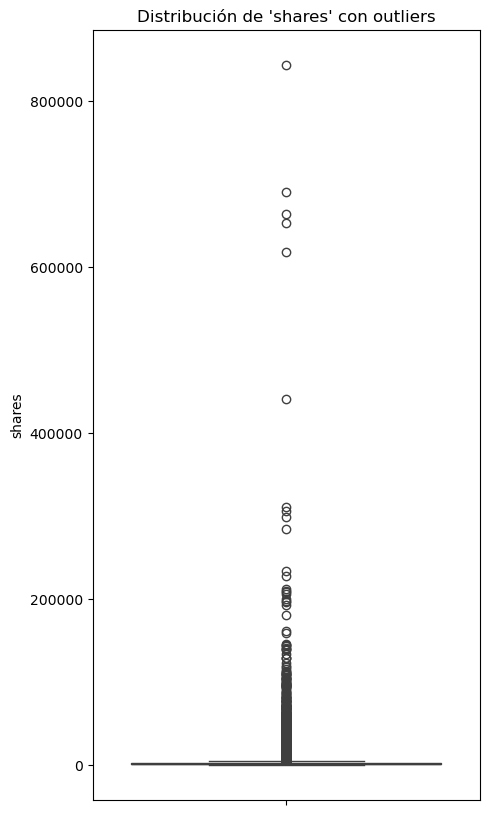

In [59]:
# Distribución gráfica de la variable 'shares' con outliers
plt.figure(figsize=(5, 10))
sns.boxplot(data=df5, y='shares') 
plt.title("Distribución de 'shares' con outliers")
plt.show()

In [61]:
# Calculamos los limites superior e inferior para después eliminar los outliers por encima y por debajo de los limites superior e inferior.

q1 = df5['shares'].quantile(0.25)
q3 = df5['shares'].quantile(0.75)

iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

In [63]:
# Procedemos a eliminar los outliers de la variable 'shares'
df5_no_outliers = df5[(df5['shares'] >= limite_inferior) & (df5['shares'] <= limite_superior)]

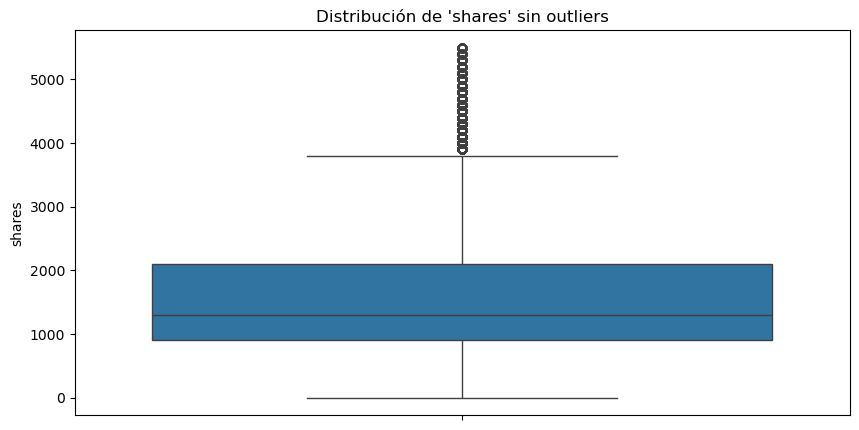

In [65]:
# Distribución gráfica de la variable 'shares' sin outliers
plt.figure(figsize=(10, 5))
sns.boxplot(data=df5_no_outliers, y='shares')
plt.title("Distribución de 'shares' sin outliers")
plt.show()

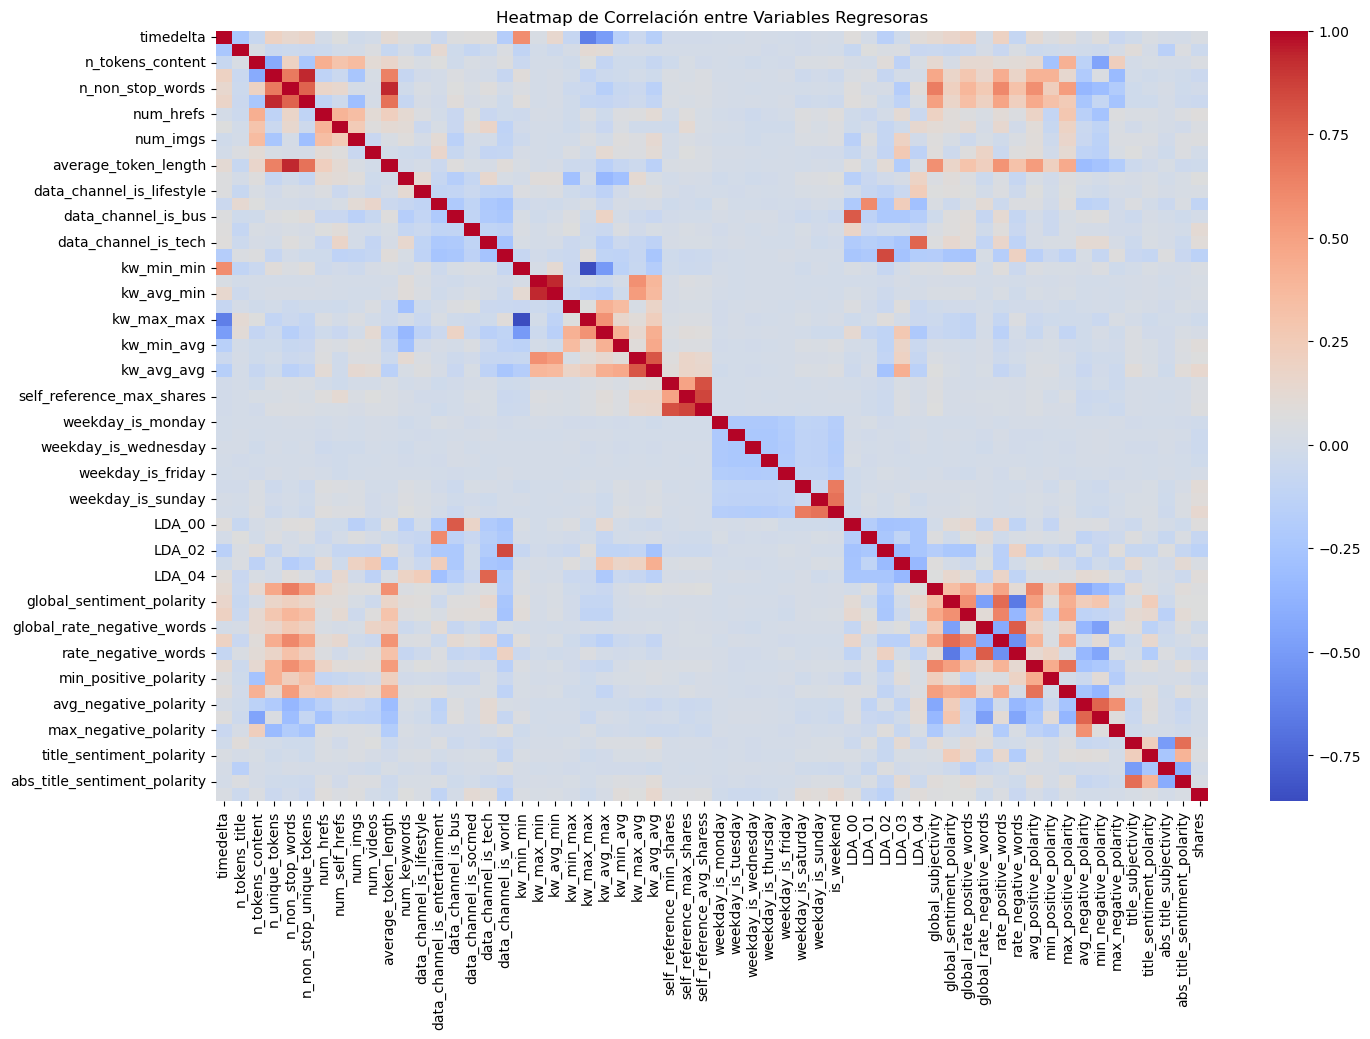

In [67]:
# Calcula y muestra graficamente las correlaciones entre las variables númericas

# Seleccionamos solamente las columnas númericas
# Por lo cual, seleccionamos solamente las columnas float e int.
numeric_df = df5_no_outliers.select_dtypes(include=[float, int])

# Calculamos la matriz de correlación
correlation_matrix = numeric_df.corr()

# Creamos el heatmap de las correlaciones
plt.figure(figsize=(16, 10))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title("Heatmap de Correlación entre Variables Regresoras")
plt.show()

Listamos aquellas variables cuyas correlaciones son mayores a 0.7 en términos absolutos

Explicación del código:
- Colocamos unstack() para convertir la matriz en una serie multiIndex (par de variables) para poder trabajar con cada par. Por otro lado, usamos reset_index() para transformar el multiIndex en columnas normales.
- correlated_pairs.columns = ['Variable 1', 'Variable 2', 'Correlation'] -> para renombrar las columnas

In [69]:
# Procedemos a idenntificar las variables con correlaciones mayores a 0.7 en términos absolutos

correlated_pairs = correlation_matrix.unstack().reset_index()
correlated_pairs.columns = ['Variable 1', 'Variable 2', 'Correlation']

correlated_pairs = correlated_pairs[
    (correlated_pairs['Variable 1'] != correlated_pairs['Variable 2']) &                     # Descartamos las filas donde la variable se compara consigo misma
    (correlated_pairs['Correlation'].abs() > 0.7)                                            # Nos quedamos con los pares cuya correlación sea mayor a 0.7
].drop_duplicates(subset=['Correlation']).sort_values(by='Correlation', ascending=False)     # Eliminamos los duplicados del mismo par de variables en orden inverso y ordenamos por correlación

print("Pares de variables con correlaciones mayores a 0.7 : \n")
print(correlated_pairs)

Pares de variables con correlaciones mayores a 0.7 : 

                      Variable 1                    Variable 2  Correlation
250             n_non_stop_words          average_token_length     0.940707
185              n_unique_tokens      n_non_stop_unique_tokens     0.937128
1160                  kw_max_min                    kw_avg_min     0.934652
1709   self_reference_max_shares    self_reference_avg_sharess     0.858243
1060       data_channel_is_world                        LDA_02     0.841251
1649   self_reference_min_shares    self_reference_avg_sharess     0.819821
1526                  kw_max_avg                    kw_avg_avg     0.797421
878          data_channel_is_bus                        LDA_00     0.784441
2808  global_rate_negative_words           rate_negative_words     0.778250
245             n_non_stop_words      n_non_stop_unique_tokens     0.757132
1002        data_channel_is_tech                        LDA_04     0.750710
3173       avg_negative_polarity 

Procedemos a eliminar una variable de cada par de ellas con correlaciones altas

In [71]:
# set de variables que vamos a eliminar
variables_a_remover = set()


for index, row in correlated_pairs.iterrows():
    if row['Variable 1'] not in variables_a_remover:
        variables_a_remover.add(row['Variable 2'])

df5_chico = df5_no_outliers.drop(columns=list(variables_a_remover))

In [73]:
variables_a_remover

{'LDA_00',
 'LDA_02',
 'LDA_04',
 'abs_title_sentiment_polarity',
 'average_token_length',
 'is_weekend',
 'kw_avg_avg',
 'kw_avg_min',
 'kw_max_max',
 'min_negative_polarity',
 'n_non_stop_unique_tokens',
 'rate_negative_words',
 'rate_positive_words',
 'self_reference_avg_sharess'}

In [75]:
# Validamos de que se haya dado correctamente
sorted(df5_chico.columns)

['LDA_01',
 'LDA_03',
 'abs_title_subjectivity',
 'avg_negative_polarity',
 'avg_positive_polarity',
 'data_channel_is_bus',
 'data_channel_is_entertainment',
 'data_channel_is_lifestyle',
 'data_channel_is_socmed',
 'data_channel_is_tech',
 'data_channel_is_world',
 'global_rate_negative_words',
 'global_rate_positive_words',
 'global_sentiment_polarity',
 'global_subjectivity',
 'kw_avg_max',
 'kw_max_avg',
 'kw_max_min',
 'kw_min_avg',
 'kw_min_max',
 'kw_min_min',
 'max_negative_polarity',
 'max_positive_polarity',
 'min_positive_polarity',
 'n_non_stop_words',
 'n_tokens_content',
 'n_tokens_title',
 'n_unique_tokens',
 'num_hrefs',
 'num_imgs',
 'num_keywords',
 'num_self_hrefs',
 'num_videos',
 'self_reference_max_shares',
 'self_reference_min_shares',
 'shares',
 'timedelta',
 'title_sentiment_polarity',
 'title_subjectivity',
 'weekday_is_friday',
 'weekday_is_monday',
 'weekday_is_saturday',
 'weekday_is_sunday',
 'weekday_is_thursday',
 'weekday_is_tuesday',
 'weekday_is_wed

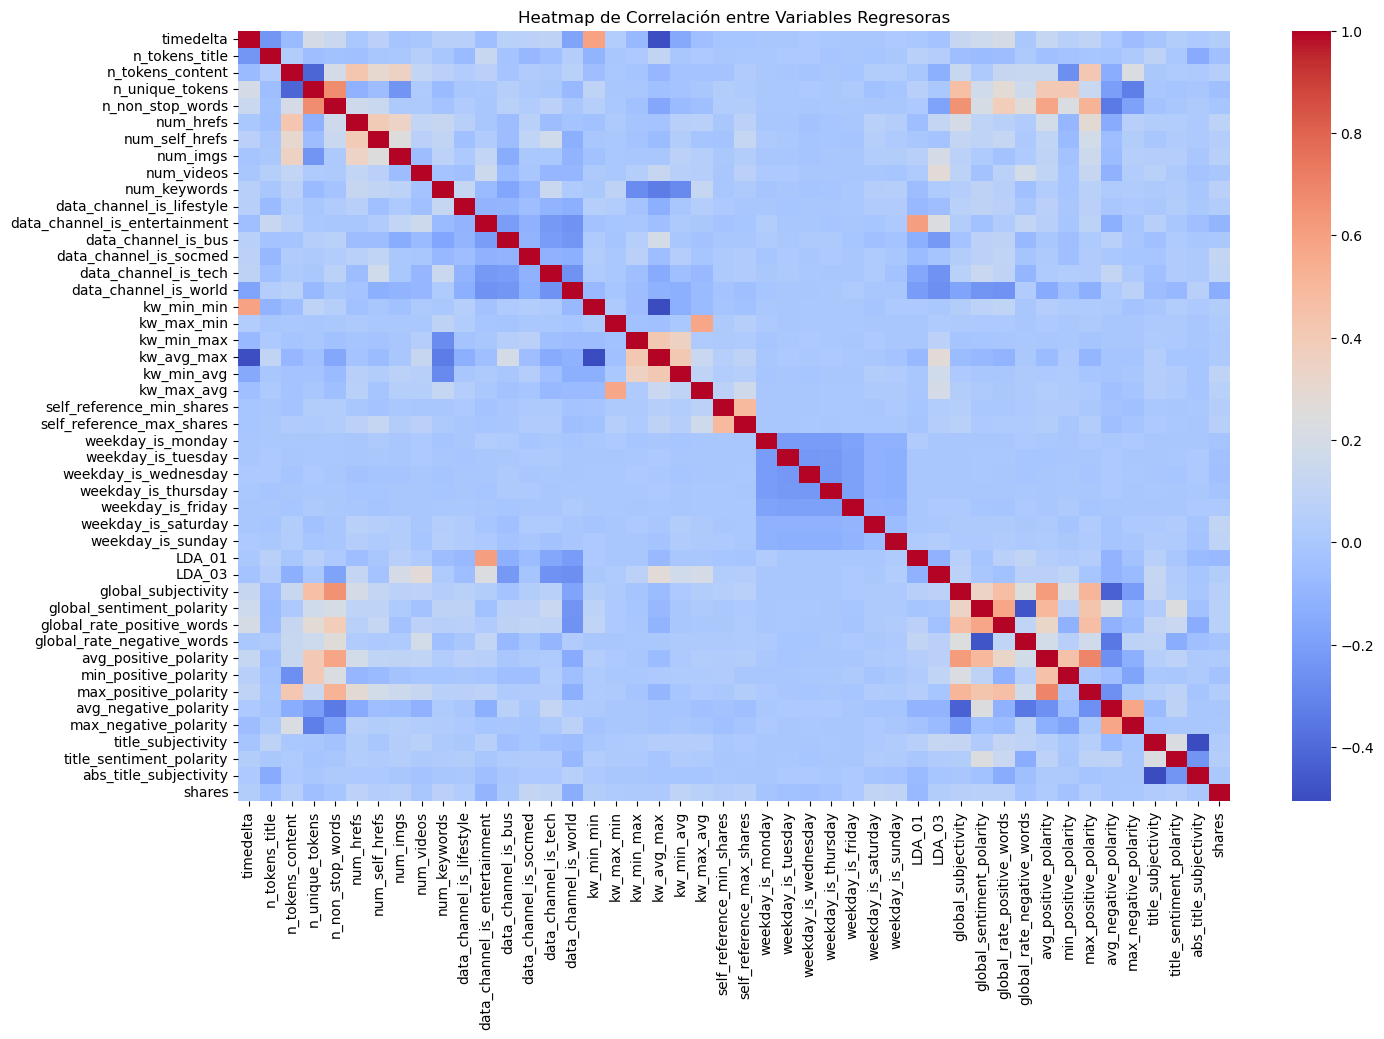

In [77]:
# Calculamos y mostramos graficamente las correlaciones entre las variables númericas después de haber eliminado algunas variables
# Las variables que se encuentran en el set variables_a_remover

# Seleccionamos solamente las columnas númericas
# Por lo cual, seleccionamos solamente las columnas float e int.
numeric_df_chico = df5_chico.select_dtypes(include=[float, int])

# Calculamos la matriz de correlación
correlation_matrix_chico = numeric_df_chico.corr()

# Creamos el heatmap de las correlaciones
plt.figure(figsize=(16, 10))
sns.heatmap(correlation_matrix_chico, annot=False, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title("Heatmap de Correlación entre Variables Regresoras")
plt.show()

#### Pregunta 7

7. Escoge cuatro variables numéricas y analiza su distribución. Luego normaliza todas las variables numéricas y divide los datos en entrenamiento y test (33%).

In [79]:
df5_no_outliers.head()

,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,0.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,0.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,0.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,0.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,0.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


In [81]:
# Creamos una lista con las variables numericas escogidas

numeric_cols4 = ['n_tokens_title', 'n_tokens_content', 'num_hrefs', 'num_imgs']

In [83]:
# Separamos las variables numericas en un dataframe llamado df7

df7 = df5_no_outliers[numeric_cols4]

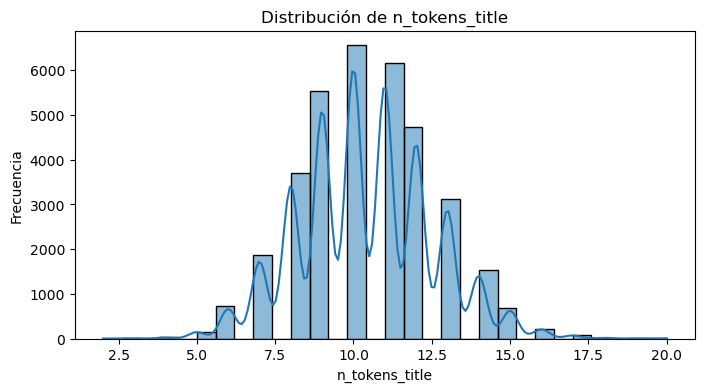

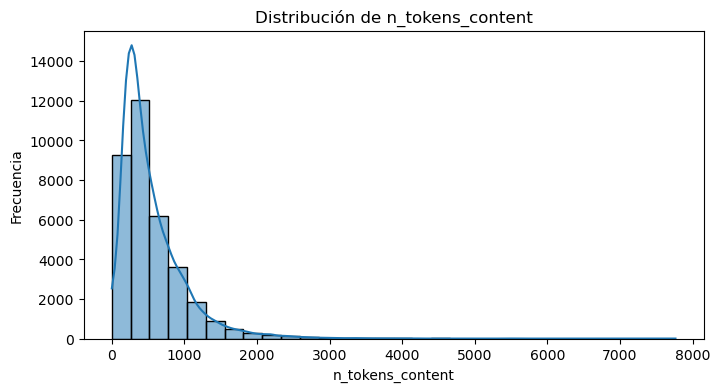

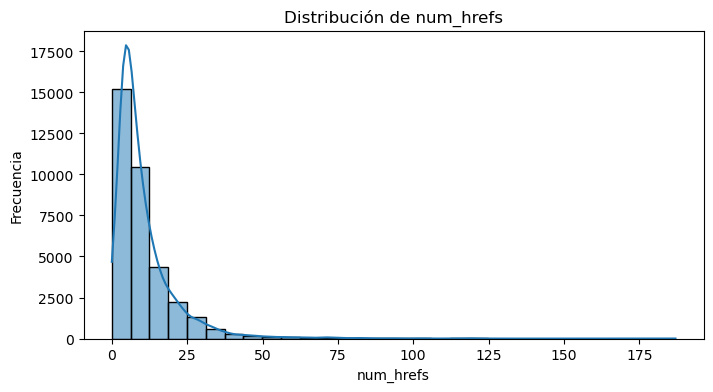

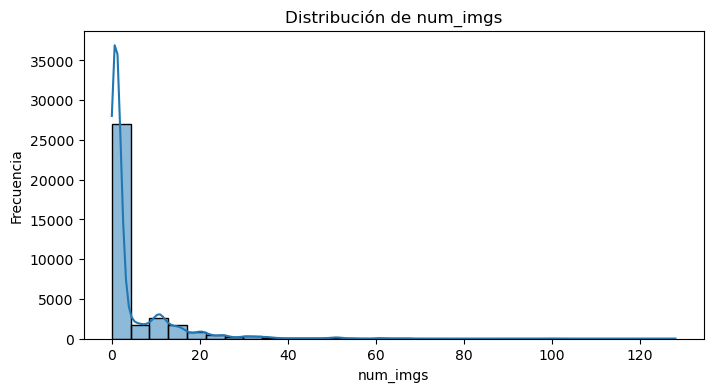

In [85]:
# Análisis de distribución de las variables numericas seleccionadas

for col in numeric_cols4:
    plt.figure(figsize=(8, 4))
    sns.histplot(df7[col], kde=True, bins=30)
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

Luego normaliza todas las variables numéricas y divide los datos en entrenamiento y test (33%).

In [87]:
df5_no_outliers.info()

<class 'pandas.core.frame.DataFrame'>
Index: 35103 entries, 0 to 39643
Data columns (total 60 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   timedelta                      35103 non-null  float64
 1   n_tokens_title                 35103 non-null  float64
 2   n_tokens_content               35103 non-null  float64
 3   n_unique_tokens                35103 non-null  float64
 4   n_non_stop_words               35103 non-null  float64
 5   n_non_stop_unique_tokens       35103 non-null  float64
 6   num_hrefs                      35103 non-null  float64
 7   num_self_hrefs                 35103 non-null  float64
 8   num_imgs                       35103 non-null  float64
 9   num_videos                     35103 non-null  float64
 10  average_token_length           35103 non-null  float64
 11  num_keywords                   35103 non-null  float64
 12  data_channel_is_lifestyle      35103 non-null  floa

In [89]:
scaler = StandardScaler()

df_scaled_array = scaler.fit_transform(df5_no_outliers.select_dtypes(include=[float, int]).drop('shares', axis=1))  # No incluimos la variable objetivo

columns_list = list(df5_no_outliers.select_dtypes(include=[float, int]).drop('shares', axis=1).columns)     # lista de las columnas númericas sin la variable objetivo 'shares'

# Colocammos los datos en el DataFrame
df_scaled = pd.DataFrame(df_scaled_array, columns = columns_list, index=df5_no_outliers.index)

# Colocamos la variable objetivo en el DataFrame
df_scaled['shares'] = df5_no_outliers['shares']

df_scaled

,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,1.751428,0.757876,-0.708421,0.985600,0.168577,0.935658,-0.611288,-0.337102,-0.412269,-0.299752,...,0.067795,-0.224642,-0.730850,-0.278982,-0.989993,0.695093,-0.984572,-1.806902,0.159994,593
1,1.751428,-0.665214,-0.630618,0.547236,0.168577,0.779660,-0.704126,-0.596986,-0.412269,-0.299752,...,-0.876302,-0.224642,1.101712,1.362505,0.073471,-0.862826,-0.263750,0.834933,-0.684726,711
2,1.751428,-0.665214,-0.725710,0.326655,0.168577,-0.072809,-0.704126,-0.596986,-0.412269,-0.299752,...,0.067795,0.997956,-1.655385,-0.970134,-0.281017,-0.862826,-0.263750,0.834933,-0.684726,1500
3,1.751428,-0.665214,-0.034129,-0.204745,0.168577,-0.061035,-0.147095,-0.856870,-0.412269,-0.299752,...,0.582757,0.182891,-0.886940,-0.278982,-0.635505,-0.862826,-0.263750,0.834933,-0.684726,1200
4,1.751428,1.232240,1.135076,-0.861287,0.168577,-0.891303,0.781289,4.080925,1.935901,-0.299752,...,-0.876302,0.997956,0.297823,0.066594,0.605203,0.553464,0.260483,-1.566735,-0.070384,505
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39639,-1.604465,0.283513,-0.433949,-0.016561,0.168577,0.066409,-0.147095,0.962318,-0.412269,-0.047385,...,0.067795,-0.020876,-0.017637,0.066594,-0.192395,-0.551242,-0.263750,0.306566,-0.684726,1800
39640,-1.604465,0.757876,-0.472851,1.229184,0.168577,1.399381,-0.147095,0.962318,-0.165094,11.813868,...,0.582757,-0.224642,0.369788,0.412170,0.073471,0.071925,3.580631,-0.750168,3.820450,1900
39641,-1.604465,-0.190851,-0.226475,-0.111136,0.168577,-0.204176,1.245482,-0.596986,0.947197,-0.047385,...,0.582757,-1.039707,-0.781879,-0.970134,-0.635505,0.553464,0.260483,-1.566735,-0.070384,1900
39642,-1.604465,-2.088305,0.292211,0.061213,0.168577,0.118842,-0.054257,-0.596986,-0.412269,-0.299752,...,-0.463259,-1.039707,0.416270,0.066594,1.004002,-0.862826,-0.263750,0.834933,-0.684726,1100


In [91]:
print(df5_no_outliers.info())
print('\n')
print(df_scaled.info())

<class 'pandas.core.frame.DataFrame'>
Index: 35103 entries, 0 to 39643
Data columns (total 60 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   timedelta                      35103 non-null  float64
 1   n_tokens_title                 35103 non-null  float64
 2   n_tokens_content               35103 non-null  float64
 3   n_unique_tokens                35103 non-null  float64
 4   n_non_stop_words               35103 non-null  float64
 5   n_non_stop_unique_tokens       35103 non-null  float64
 6   num_hrefs                      35103 non-null  float64
 7   num_self_hrefs                 35103 non-null  float64
 8   num_imgs                       35103 non-null  float64
 9   num_videos                     35103 non-null  float64
 10  average_token_length           35103 non-null  float64
 11  num_keywords                   35103 non-null  float64
 12  data_channel_is_lifestyle      35103 non-null  floa

##### Dividimos los datos en entrenamiento y test (33%).

In [95]:
X_scaled = df_scaled.loc[:, df_scaled.columns != 'shares']
y = df_scaled['shares']

X_train_scaled, X_test_scaled, y_train, y_test = train_test_split(X_scaled, y, test_size=.33, random_state=1234)

#### Pregunta 8

8. Entrena un modelo de Random Forest usando búsqueda de grilla. La búsqueda debe considerar:
   - para **n_estimators**, valores entre 100 y 300 para 10 valores
   - para **max_depth**, valores entre 2 y 15 para 10 valores
   - para **max_features**, buscar para "sqrt" y "log2".

   En la búsqueda de grilla considera cinco fold. Muestra los mejores hiperparámetros encontrados por la búsqueda de grilla. Calcula dos métricas sobre el conjunto de test, para evaluar el modelo.

In [97]:
X = df5_no_outliers.loc[:, df5_no_outliers.columns != 'shares']
y = df5_no_outliers['shares']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.33, random_state=1234)

In [99]:
# Parámetros para la búsqueda de grilla
param_grid = {
    'n_estimators': np.linspace(100, 300, 10, dtype=int),
    'max_depth': np.linspace(2, 15, 10, dtype=int),
    'max_features': ['sqrt', 'log2']
}

# Intanciamos el modelo de Random Forest Regressor
rf_model = RandomForestRegressor(random_state=42)

# Configuramos el Grid Search con validación cruzada de 5 folds
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',  # ColocamosMSE como métrica de evaluación
    cv=5,
    verbose=1,
    n_jobs=-1
)

# Entrenamos el modelo
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 200 candidates, totalling 1000 fits


GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': array([ 2,  3,  4,  6,  7,  9, 10, 12, 13, 15]),
                         'max_features': ['sqrt', 'log2'],
                         'n_estimators': array([100, 122, 144, 166, 188, 211, 233, 255, 277, 300])},
             scoring='neg_mean_squared_error', verbose=1)

In [100]:
# Mostramos los mejores hiperparámetros encontrados por la búsqueda de grilla
best_params = grid_search.best_params_
print("Mejores hiperparámetros encontrados por la búsqueda de grilla: \n", best_params)

Mejores hiperparámetros encontrados por la búsqueda de grilla: 
 {'max_depth': 15, 'max_features': 'sqrt', 'n_estimators': 300}


In [101]:
# Mejor modelo encontrado por la búsqueda de grilla, tiene los hiperparámetros optimos
best_model = grid_search.best_estimator_

# Evaluamos el rendimiento del modelo
y_pred = best_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('Metricas en el conjunto de prueba : \n')

print("MSE del mejor modelo encontrado por la búsqueda de grilla: \n", mse)
print("R2 del mejor modelo encontrado por la búsqueda de grilla: \n", r2)

Metricas en el conjunto de prueba : 

MSE del mejor modelo encontrado por la búsqueda de grilla: 
 1044730.1813963043
R2 del mejor modelo encontrado por la búsqueda de grilla: 
 0.1368362893526346


In [102]:
# datos con la importancia de cada variable
importances = best_model.feature_importances_

# nombre de las variables
feature_names = X_train.columns

# Generamos un DataFrame
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# Ordenamos el DataFrame
importance_df = importance_df.sort_values(by='Importance', ascending=False)

In [103]:
importance_df.head()

,Feature,Importance
26,kw_avg_avg,0.045876
25,kw_max_avg,0.039430
29,self_reference_avg_sharess,0.032058
27,self_reference_min_shares,0.031326
39,LDA_01,0.030564


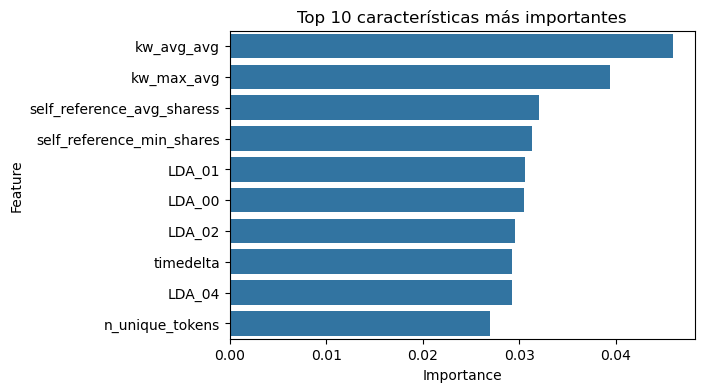

In [104]:
plt.figure(figsize=(6, 4))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(10))
plt.title('Top 10 características más importantes')
plt.show()

#### Pregunta 9

9. Entrena un modelo de red neuronal Fully Connected con al menos dos capas ocultas y aplicando regularización Dropout. Utiliza en cada capa una cantidad de neuronas mayor a 300. Calcula las mismas métricas usadas en el modelo anterior, sobre el conjunto de test, para evaluar el modelo.

In [ ]:
df_scaled['shares'].value_counts(dropna=False)

In [ ]:
# Creación del modelo
ann_model = Sequential([
    Dense(512, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),  # Regularización Dropout
    Dense(384, activation='relu'),
    Dropout(0.3),  # Regularización Dropout
    Dense(256, activation='relu'),
    Dropout(0.3),  # Regularización Dropout
    Dense(1, activation='linear')  # Capa de salida para regresión
])

# Compilación del modelo
ann_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Entrenamiento del modelo
history = ann_model.fit(
    X_train_scaled, y_train,
    validation_data=(X_test_scaled, y_test),
    epochs=20,
    batch_size=32,
    verbose=1
)

# Predicciones del modelo
y_pred = ann_model.predict(X_test).flatten()

In [ ]:
# Evaluamos el rendimiento del modelo

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('Metricas en el conjunto de prueba : \n')

print("MSE del modelo: ", mse)
print("R2 del modelo: ", r2)

In [ ]:
# Visualización de la pérdida

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Pérdida entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida validación')
plt.title('Pérdida durante el entrenamiento')
plt.xlabel('Épocas')
plt.ylabel('MSE')
plt.legend()
plt.show()

#### Pregunta 10

10. Implementa y entrena un modelo Extreme Gradient Boosting, usando búsqueda de grilla con 5 fold. Para ello considera:
    - **n_estimators**: [100, 120, 150, 200, 300]
    - **learning_rate**: [0.008, 0.07, 0.009, 0.01, 0.02]
    - **subsample**: np.linspace(0.05, 1, 5)
    - **scale_pos_weight**: np.linspace(0.8, 0.9, 2)

Muestra los mejores hiperparámetros encontrados, calcula y muestra gráficamente la importancia de las características para la predicción en el modelo. Calcula las mismas métricas usadas en el modelo anterior, sobre el conjunto de test, para evaluar el modelo.

In [ ]:
#pip install --upgrade xgboost

In [ ]:
#pip install --upgrade scikit-learn

In [105]:
# Busqueda de grilla
param_grid = {
    "n_estimators": [100, 120, 150, 200, 300],
    "learning_rate": [0.008, 0.07, 0.009, 0.01, 0.02],
    "subsample": np.linspace(0.05, 1, 5),
    "scale_pos_weight": np.linspace(0.8, 0.9, 2),
}

# Instaciamos el modelo XGBRegressor
xgb = XGBRegressor(objective="reg:squarederror", random_state=42)

# Configuramos el grid search con validación cruzada de 5 folds
grid_search_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=5,
    verbose=1,
    n_jobs=-1,
)

# Entrenamiento el modelo
grid_search_xgb.fit(X_train, y_train)

Fitting 5 folds for each of 250 candidates, totalling 1250 fits


GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=None, m...
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, num_parallel_tree=None,
                                    random_state=42, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.008, 0.07, 0.009, 0.01, 0.02],
                         'n_estimators': [100, 120, 150, 200, 300],
                         'scale_pos_weight': array([0.8, 0.9]),
                         'subsample': array([0.05  , 0.2875, 0.525 , 0.7625, 1.    ])},
             scoring='neg_mean_squared_error', verbose=1)

In [106]:
# Mejores hiperparámetros encontrados
best_params = grid_search_xgb.best_params_
print("Mejores hiperparámetros encontrados:", best_params)

Mejores hiperparámetros encontrados: {'learning_rate': 0.02, 'n_estimators': 300, 'scale_pos_weight': 0.8, 'subsample': 0.525}


In [107]:
# Modelo optimizado
best_xgb_model = grid_search_xgb.best_estimator_

# Predicciones en el conjunto de prueba
y_pred = best_xgb_model.predict(X_test)

In [108]:
# Evaluamos el rendimiento del modelo

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('Metricas en el conjunto de prueba : \n')

print("MSE del modelo: ", mse)
print("R2 del modelo: ", r2)

Metricas en el conjunto de prueba : 

MSE del modelo:  1032108.875
R2 del modelo:  0.1472640037536621


In [109]:
# datos con la importancia de cada variable
importances = best_xgb_model.feature_importances_

# nombre de las variables
feature_names = X_train.columns

# Generamos un DataFrame
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# Ordenamos el DataFrame
importance_df = importance_df.sort_values(by='Importance', ascending=False)

In [110]:
importance_df.head()

,Feature,Importance
13,data_channel_is_entertainment,0.087895
16,data_channel_is_tech,0.050020
37,is_weekend,0.042094
17,data_channel_is_world,0.040634
15,data_channel_is_socmed,0.040121


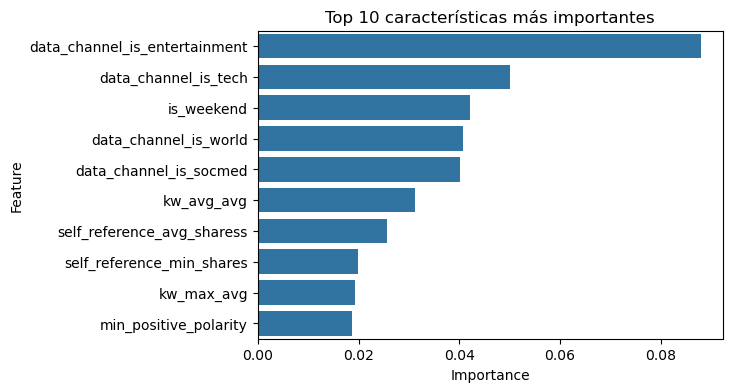

In [111]:
plt.figure(figsize=(6, 4))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(10))
plt.title('Top 10 características más importantes')
plt.show()

#### Pregunta 11

11. Construye un modelo de Bagging usando al menos tres modelos heterogéneos. Para ello utiliza la siguiente función (utilizando el archivo entregado):

```python
import util_bagging as ubagging
ubagging.bagging_het

Calcula las mismas métricas usadas en el modelo anterior, sobre el conjunto de test, para evaluar el modelo.

Muestra en un DataFrame los resultados de todos los modelos y concluye.

In [ ]:
# Importamos la funcion

from util_bagging import bagging_het

estimators = [
    DecisionTreeRegressor(max_depth=5, random_state=42),
    RandomForestRegressor(n_estimators=150, random_state=42),
    GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
]

# utilizamos la funcion bagging_het
T= 200
trained_models, yhat_test, yhat_out, idx_oob = bagging_het(X_train, y_train, T, estimators, X_test)

In [ ]:
# Evaluación el rendimiento del modelo
mse = mean_squared_error(y_test, yhat_out)
r2 = r2_score(y_test, yhat_out)

print("MSE del modelo Bagging:", mse)
print("R2 del modelo Bagging:", r2)

In [ ]:
modelos = ['Decision Tree', 'Random Forest', 'Gradient Boosting']
r2s = []
mses = []

# Hacemos un bucle para entrenar cada uno de los modelos y obtener sus metricas
for model in estimators:

  # Entrenamos el modelo
  model.fit(X_train, y_train)

  # Realizamos la prediccion del modelo
  y_pred_model = model.predict(X_test)

  # Agregamos las metricas a las listas r2s y mses de cada uno de los modelos
  r2s.append(r2_score(y_test, y_pred_model))
  mses.append(mean_squared_error(y_test, y_pred_model))

modelos.append('Bagging')
r2s.append(r2)
mses.append(mse)

resultados = pd.DataFrame({'modelo': modelos, 'r2': r2s, 'mse': mses})

In [ ]:
resultados